## Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from obspy import read, UTCDateTime as utc
from datetime import datetime, timezone
from glob import glob
import torch
import seisbench.models as sbm
import os
from tqdm import tqdm

## Load DL picker model

In [2]:
pn_model = sbm.PhaseNet.from_pretrained("stead")
# eqt_model = sbm.EQTransformer.from_pretrained("original")

In [3]:
device=torch.device("cpu")
# device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
pn_model.to(device);

## Load station table

In [4]:
station_table=pd.read_csv("/home/msseo/works/10.Earthquake_cycle_project/Gwangyang_sequence/station_table/used_stations_100km.csv", sep=",")
station_table.head()

,Network,Code,Latitude,Longitude,Elevation,Sensor
0,KS,BAU,35.1027,127.5968,562.0,EL
1,KS,BLLA,34.8646,127.4638,45.0,HG
2,KS,CGPA,34.8768,126.9710,144.0,HG
3,KS,CGWB,35.1705,128.5725,91.0,HH
4,KS,CHDA,34.2368,127.2496,87.0,HG


## Picking for all event-station waveform pairs

### No windowing

In [7]:
def get_time(pick): return pick.peak_time if hasattr(pick, 'peak_time') else pick.start_time
def get_prob(pick): return pick.peak_value if hasattr(pick, 'peak_value') else pick.probability

p_threshold, s_threshold=0.2, 0.2

eventdir_list = glob("/home/msseo/works/10.Earthquake_cycle_project/Gwangyang_sequence/waveforms_100km/20*")

for eventdir in eventdir_list:
    event_id = os.path.basename(eventdir)
    pick_results = []

    for i in range(len(station_table)):
        network, station, channel = station_table["Network"][i], station_table["Code"][i], station_table["Sensor"][i]
        
        try:
            # 1. 파형 읽기 및 스트림 병합
            stream = read().clear()
            stream += read(f"{eventdir}/{event_id}.{network}.{station}.{channel}Z.sac")
            stream += read(f"{eventdir}/{event_id}.{network}.{station}.{channel}N.sac")
            stream += read(f"{eventdir}/{event_id}.{network}.{station}.{channel}E.sac")
            
            # 파형 시간축 동기화 (오류 방지)
            t_start, t_end = max([tr.stats.starttime for tr in stream]), min([tr.stats.endtime for tr in stream])
            stream.trim(t_start, t_end)
            
            stream_filt = stream.copy().detrend("demean").filter("bandpass", freqmin=1.0, freqmax=40.0, corners=4, zerophase=True).detrend("demean") # .taper(0.05)
            
            # 2. PhaseNet 예측
            outputs = pn_model.classify(stream_filt, P_threshold=p_threshold, S_threshold=s_threshold)
            
            # 3. P, S파 후처리 로직 적용
            p_picks = [p for p in outputs.picks if p.phase == "P"]
            best_p = max(p_picks, key=get_prob) if p_picks else None

            s_picks = [s for s in outputs.picks if s.phase == "S"]
            if best_p:
                best_p_time = get_time(best_p)
                s_picks = [s for s in s_picks if get_time(s) > best_p_time]
            best_s = max(s_picks, key=get_prob) if s_picks else None

            # 4. 결과 누적
            for pick in (best_p, best_s):
                if pick is not None:
                    pick_results.append({
                        "Event_ID": event_id,
                        "Network": network,
                        "Station": station,
                        "Phase": pick.phase,
                        "Time": get_time(pick),
                        "Probability": round(get_prob(pick), 3)
                    })
                    
        except Exception as e:
            # 파일이 없거나 오류 발생 시 콘솔에 알림 후 다음 관측소로 진행
            print(f"Skipped {station} for event {event_id} (Reason: {e})")

    # 5. 이벤트별 결과를 DataFrame으로 변환 후 CSV 저장
    if pick_results:
        df_picks = pd.DataFrame(pick_results)
        output_csv = f"./picks/{event_id}_picks.csv"
        df_picks.to_csv(output_csv, index=False)
        print(f"Saved: {output_csv}")

Skipped SIDA for event 20210720161418 (Reason: [Errno 2] No such file or directory: '/home/msseo/works/10.Earthquake_cycle_project/Gwangyang_sequence/waveforms_100km/20210720161418/20210720161418.KS.SIDA.HGZ.sac')
Saved: ./picks/20210720161418_picks.csv
Skipped SIDA for event 20210827002315 (Reason: [Errno 2] No such file or directory: '/home/msseo/works/10.Earthquake_cycle_project/Gwangyang_sequence/waveforms_100km/20210827002315/20210827002315.KS.SIDA.HGZ.sac')
Saved: ./picks/20210827002315_picks.csv
Skipped SIDA for event 20210827220322 (Reason: [Errno 2] No such file or directory: '/home/msseo/works/10.Earthquake_cycle_project/Gwangyang_sequence/waveforms_100km/20210827220322/20210827220322.KS.SIDA.HGZ.sac')
Saved: ./picks/20210827220322_picks.csv
Skipped SIDA for event 20210828133410 (Reason: [Errno 2] No such file or directory: '/home/msseo/works/10.Earthquake_cycle_project/Gwangyang_sequence/waveforms_100km/20210828133410/20210828133410.KS.SIDA.HGZ.sac')
Saved: ./picks/202108281

### Windowing

In [10]:
def get_time(pick): return pick.peak_time if hasattr(pick, 'peak_time') else pick.start_time
def get_prob(pick): return pick.peak_value if hasattr(pick, 'peak_value') else pick.probability
def to_abs_time(t, ref_time): return ref_time + t if isinstance(t, (int, float)) else utc(t)

p_threshold, s_threshold = 0.2, 0.2
max_sp_gap = 15.0  

evdp, vp, vs = 15.0, 5.9, 3.0
win_p_offset, win_s_offset = -1.0, 4.0

eventdir_list = sorted(glob("/home/msseo/works/10.Earthquake_cycle_project/Gwangyang_sequence/waveforms_100km/20*"))

for eventdir in eventdir_list:
    event_id = os.path.basename(eventdir)
    pick_results = []
    print(f"\n--- Processing Event: {event_id} ---")

    for i in range(len(station_table)):
        network, station, channel = station_table["Network"][i], station_table["Code"][i], station_table["Sensor"][i]
        
        f_z = f"{eventdir}/{event_id}.{network}.{station}.{channel}Z.sac"
        f_n = f"{eventdir}/{event_id}.{network}.{station}.{channel}N.sac"
        f_e = f"{eventdir}/{event_id}.{network}.{station}.{channel}E.sac"
        
        if not (os.path.exists(f_z) and os.path.exists(f_n) and os.path.exists(f_e)):
            print(f"[Skip] {station}: 3성분 파형 파일 누락")
            continue
            
        try:
            stream = read().clear()
            stream += read(f_z)
            stream += read(f_n)
            stream += read(f_e)
            
            tr_z = stream.select(component="Z")[0]
            
            # 'o' 헤더 조건 삭제, 'dist' 헤더 유무만 확인
            if not hasattr(tr_z.stats.sac, 'dist') or tr_z.stats.sac.dist == -12345.0:
                print(f"[Skip] {station}: SAC 헤더(dist) 누락")
                continue
            
            sac = tr_z.stats.sac
            hypo_dist = np.hypot(sac.dist, evdp)
            
            # 제안하신 방식: starttime - b = 지진 발생 기준 시간(Origin time)
            origin_time_abs = tr_z.stats.starttime - sac.b
            
            # 위상 속도 기반 윈도우 계산 (오리지널 로직)
            win_start = origin_time_abs + (hypo_dist / vp) + win_p_offset
            win_end = origin_time_abs + (hypo_dist / vs) + win_s_offset

            t_start, t_end = max([tr.stats.starttime for tr in stream]), min([tr.stats.endtime for tr in stream])
            stream.trim(t_start, t_end)
            stream_filt = stream.copy().detrend("demean").filter("bandpass", freqmin=1.0, freqmax=40.0, corners=4, zerophase=True).detrend("demean")
            
            outputs = pn_model.classify(stream_filt, P_threshold=p_threshold, S_threshold=s_threshold)
            
            # 윈도우 내부의 Pick만 필터링 (오리지널 로직)
            p_picks = sorted([p for p in outputs.picks if p.phase == "P" and win_start <= to_abs_time(get_time(p), t_start) <= win_end], key=get_time)
            s_picks = sorted([s for s in outputs.picks if s.phase == "S" and win_start <= to_abs_time(get_time(s), t_start) <= win_end], key=get_time)
            
            # S-P 간격을 만족하는 최적 쌍 검색 (오리지널 로직)
            valid_pairs = [(p, s) for p in p_picks for s in s_picks if 0 < get_time(s) - get_time(p) < max_sp_gap]
            best_p, best_s = max(valid_pairs, key=lambda x: get_prob(x[0]) + get_prob(x[1])) if valid_pairs else (None, None)

            # 쌍이 없을 경우 단일 위상 피킹 처리 (오리지널 로직)
            if not best_p and p_picks: best_p = max(p_picks, key=get_prob)
            if not best_s and s_picks: best_s = max([s for s in s_picks if get_time(s) > get_time(best_p)], key=get_prob) if best_p else max(s_picks, key=get_prob)

            for pick in (best_p, best_s):
                if pick is not None:
                    pick_results.append({"Event_ID": event_id, "Network": network, "Station": station, "Phase": pick.phase, "Time": get_time(pick), "Probability": round(get_prob(pick), 3)})
                    
        except Exception as e:
            print(f"[Error] {station}: {e}")

    if pick_results:
        os.makedirs("./picks", exist_ok=True)
        df_picks = pd.DataFrame(pick_results)
        output_csv = f"./picks/{event_id}_picks.csv"
        df_picks.to_csv(output_csv, index=False)
        print(f"Saved: {output_csv} (Total picks: {len(pick_results)})")
    else:
        print(f"No picks saved for {event_id}.")


--- Processing Event: 20210720161418 ---
[Skip] SIDA: 3성분 파형 파일 누락
Saved: ./picks/20210720161418_picks.csv (Total picks: 66)

--- Processing Event: 20210827002315 ---
[Skip] SIDA: 3성분 파형 파일 누락
Saved: ./picks/20210827002315_picks.csv (Total picks: 97)

--- Processing Event: 20210827220322 ---
[Skip] SIDA: 3성분 파형 파일 누락
Saved: ./picks/20210827220322_picks.csv (Total picks: 104)

--- Processing Event: 20210828133410 ---
[Skip] SIDA: 3성분 파형 파일 누락
Saved: ./picks/20210828133410_picks.csv (Total picks: 102)

--- Processing Event: 20210828133922 ---
[Skip] SIDA: 3성분 파형 파일 누락
Saved: ./picks/20210828133922_picks.csv (Total picks: 65)

--- Processing Event: 20210828234556 ---
[Skip] JEU2: 3성분 파형 파일 누락
[Skip] SIDA: 3성분 파형 파일 누락
Saved: ./picks/20210828234556_picks.csv (Total picks: 99)

--- Processing Event: 20260101024947 ---
[Skip] GMNA: 3성분 파형 파일 누락
[Skip] HADA: 3성분 파형 파일 누락
[Skip] TOY2: 3성분 파형 파일 누락
[Skip] YGJA: 3성분 파형 파일 누락
[Skip] YOA: 3성분 파형 파일 누락
[Skip] BOSB: 3성분 파형 파일 누락
[Skip] KUJA: 3성분 파형

## Add P/S pick information to `SAC` header

In [11]:
pick_table_list = sorted(glob("/home/msseo/works/10.Earthquake_cycle_project/Gwangyang_sequence/picks/*.csv"))

for pick_table in tqdm(pick_table_list):
    table = pd.read_csv(pick_table, sep=",")
    if table.empty: continue
    
    event_id = table["Event_ID"][0]
    
    for _, row in table.iterrows():
        phase, pick_time = row["Phase"], utc(row["Time"])
        network, station = row["Network"], row["Station"]
        channel = station_table[station_table["Code"]==station].reset_index(drop=True)["Sensor"][0]
        
        for comp in ["Z", "N", "E"]:
            sac_file = f"/home/msseo/works/10.Earthquake_cycle_project/Gwangyang_sequence/waveforms_100km/{event_id}/{event_id}.{network}.{station}.{channel}{comp}.sac"
            
            try:
                tr = read(sac_file)[0]
                trace_origin = tr.stats.starttime - tr.stats.sac.b
                time_diff = pick_time - trace_origin
                
                if phase == "P": tr.stats.sac.a = time_diff
                elif phase == "S": tr.stats.sac.t0 = time_diff
                
                tr.write(sac_file, format="SAC")
                
            except Exception as e:
                print(f"Error processing {sac_file}: {e}")

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████| 11/11 [00:17<00:00,  1.61s/it]


## Record section for phase pick check

In [21]:
def plot_record_section(event_id, comp="Z", scale=2.0):
    files = glob(f"/home/msseo/works/10.Earthquake_cycle_project/Gwangyang_sequence/waveforms_100km/{event_id}/*{comp}.sac")
    plt.figure(figsize=(12, 10))
    
    for f in files:
        tr = read(f)[0].copy().detrend("demean").filter("highpass", freq=1.0, corners=4, zerophase=False).detrend("demean")
        
        # SAC 헤더에 거리(dist) 정보가 없으면 해당 관측소는 건너뜀
        if not hasattr(tr.stats.sac, 'dist'): continue
        dist = tr.stats.sac.dist
        
        # 파형 정규화 및 기준 시간에 맞춘 시간축 생성
        data = tr.data / np.max(np.abs(tr.data))
        times = tr.times(reftime=tr.stats.starttime - tr.stats.sac.b)
        
        # 파형을 Y축(거리) 기준으로 이동시켜 플롯 (인자 줄바꿈 최소화)
        plt.plot(times, data * scale + dist, "k", lw=0.5)
        
        # P파(a) 및 S파(t0) 마커 표출
        if hasattr(tr.stats.sac, 'a') and tr.stats.sac.a != -12345.0:
            plt.plot(tr.stats.sac.a, dist, "b|", ms=15, mew=2, label="P" if "P" not in plt.gca().get_legend_handles_labels()[1] else "")
        if hasattr(tr.stats.sac, 't0') and tr.stats.sac.t0 != -12345.0:
            plt.plot(tr.stats.sac.t0, dist, "r|", ms=15, mew=2, label="S" if "S" not in plt.gca().get_legend_handles_labels()[1] else "")
            
    plt.xlabel("Time [s]")
    plt.ylabel("Distance [km]")
    plt.xlim(-10, 50)
    plt.title(f"Record Section for Event {event_id} ({comp} comp)")
    plt.legend(loc="upper right")
    plt.show();

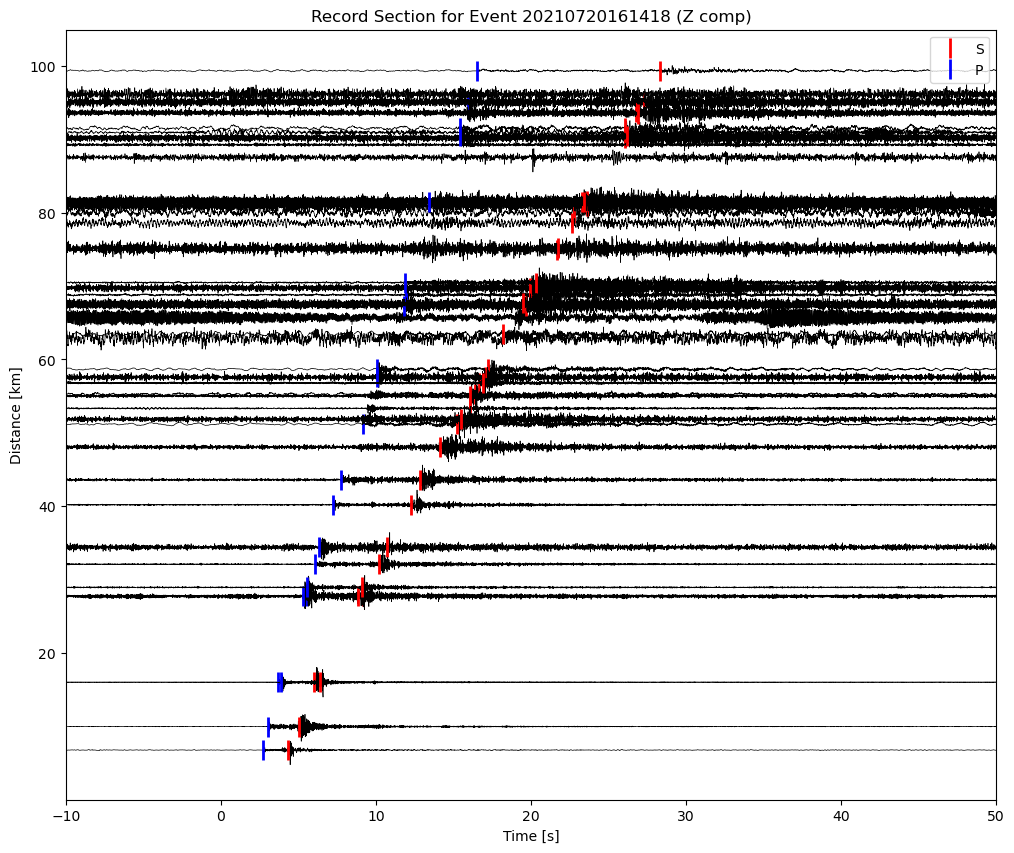

In [22]:
plot_record_section("20210720161418", comp="Z")

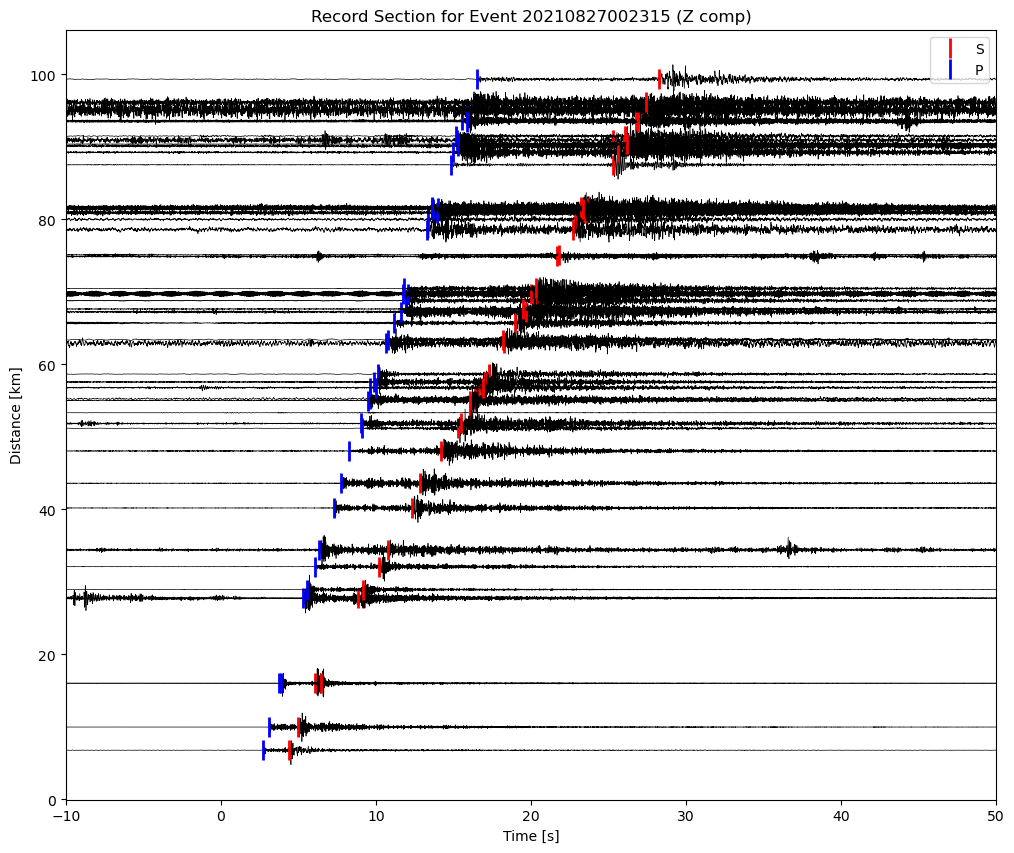

In [23]:
plot_record_section("20210827002315", comp="Z")

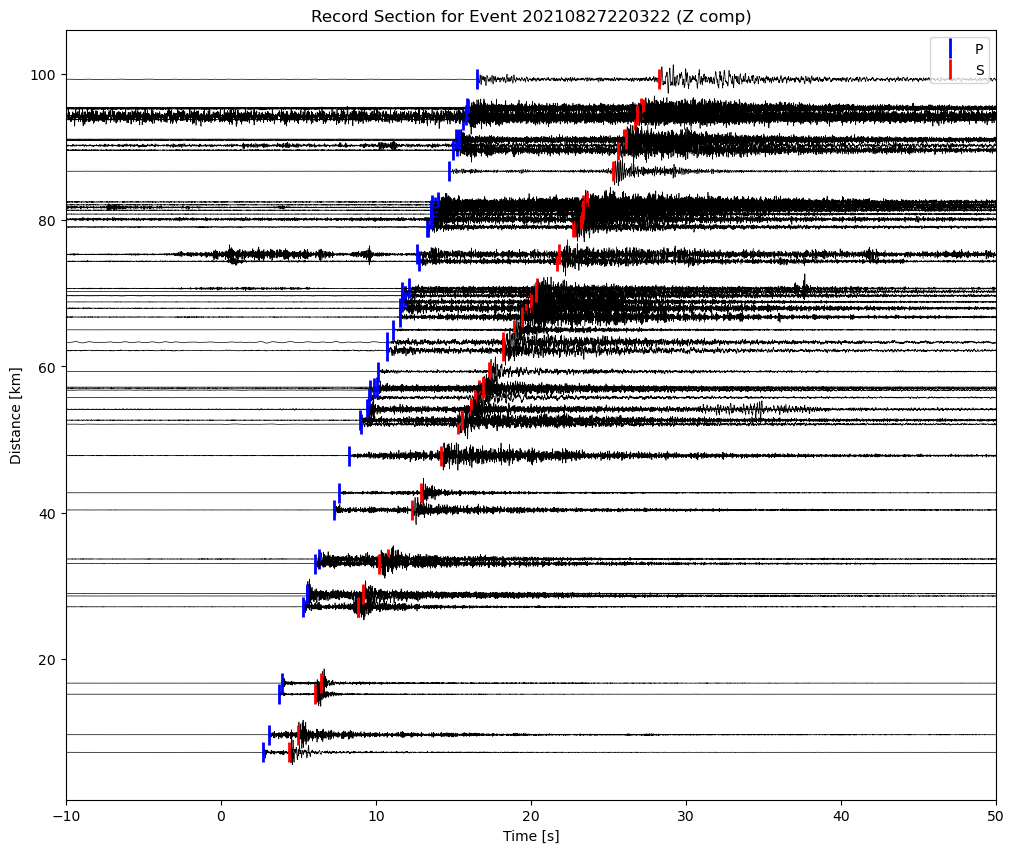

In [24]:
plot_record_section("20210827220322", comp="Z")

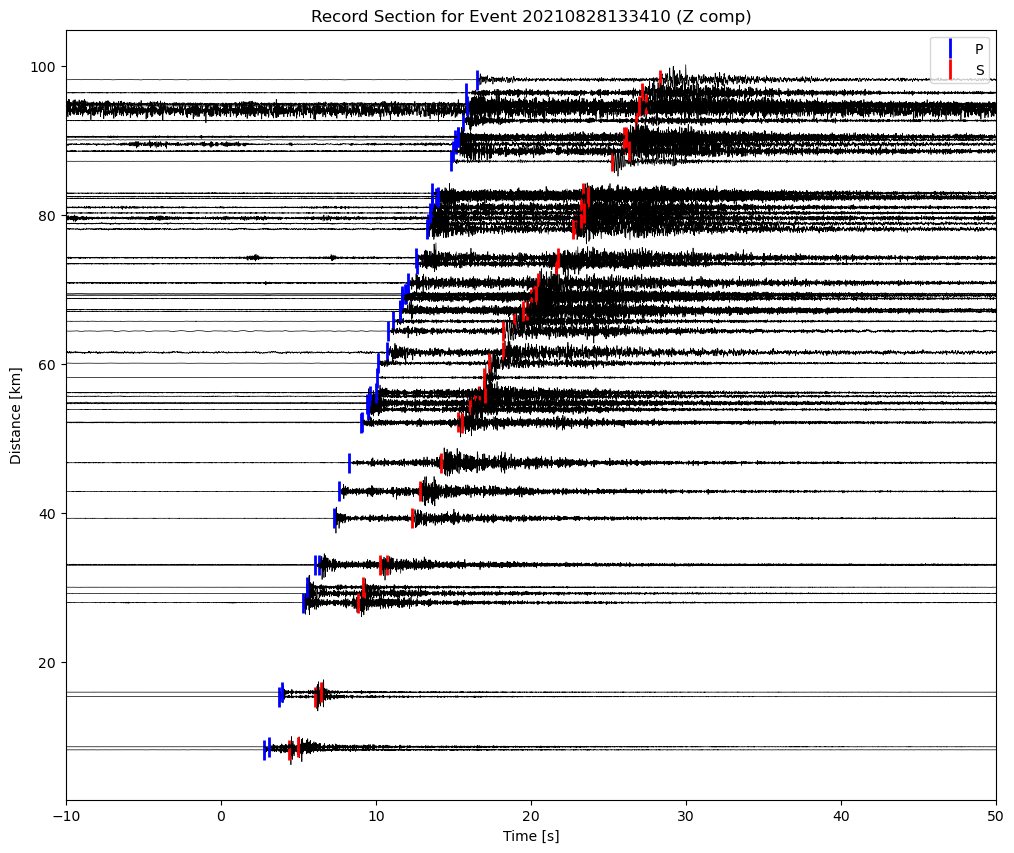

In [25]:
plot_record_section("20210828133410", comp="Z")

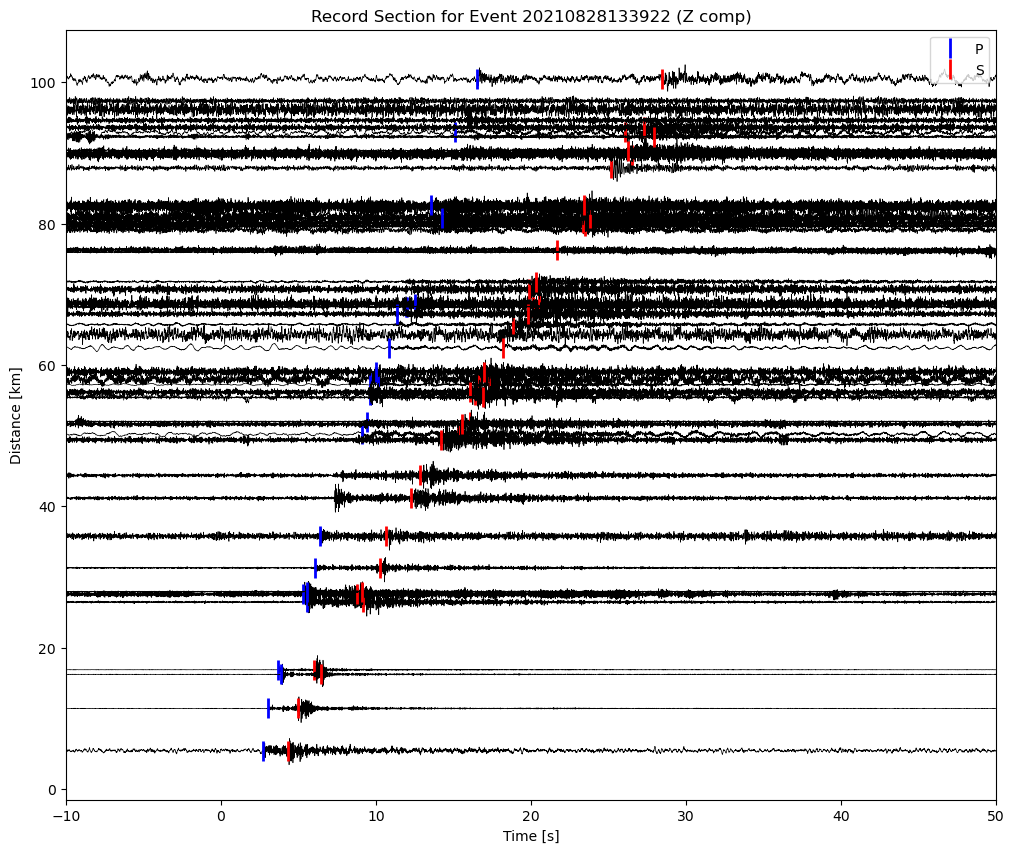

In [26]:
plot_record_section("20210828133922", comp="Z")

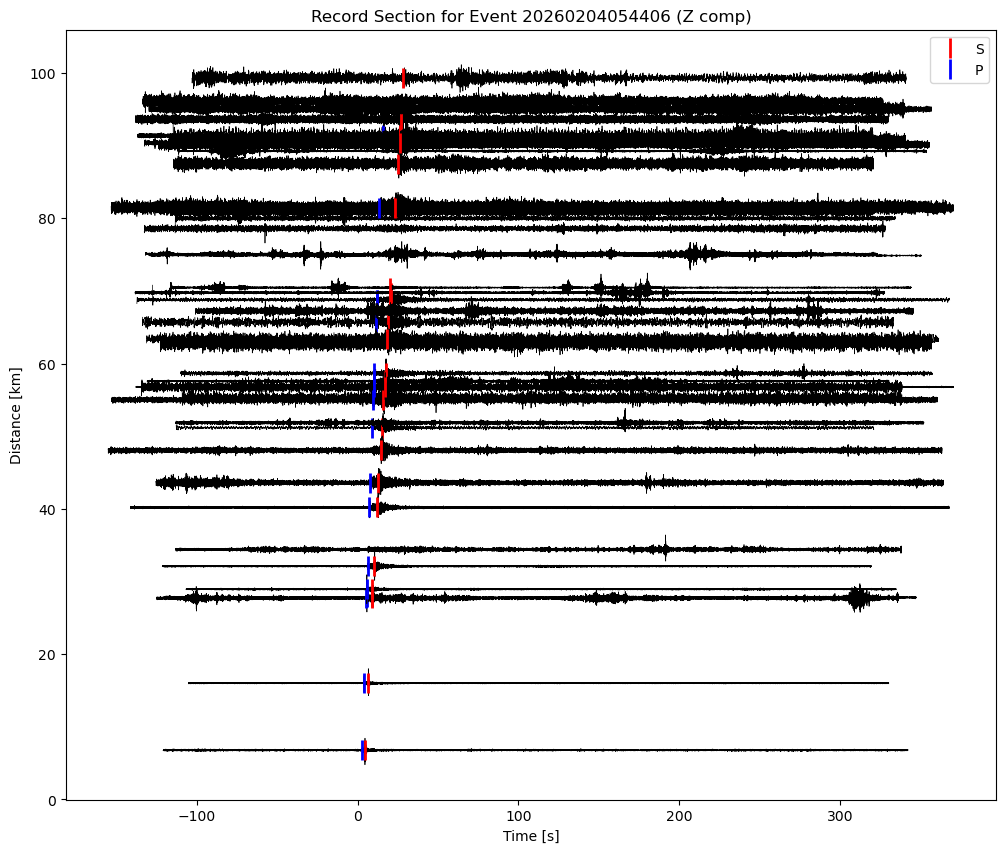

In [20]:
plot_record_section("20260204054406", comp="Z")